# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Vincent Valentino | 5054251016 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
import copy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

torch.manual_seed(42)
np.random.seed(42)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Using device:', device)

Using device: cuda


In [2]:
train_df = pd.read_csv('fashion-mnist_train.csv')
test_df = pd.read_csv('fashion-mnist_test.csv')

print('Train shape:', train_df.shape)
print('Test shape:', test_df.shape)
display(train_df.head())

Train shape: (60000, 785)
Test shape: (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


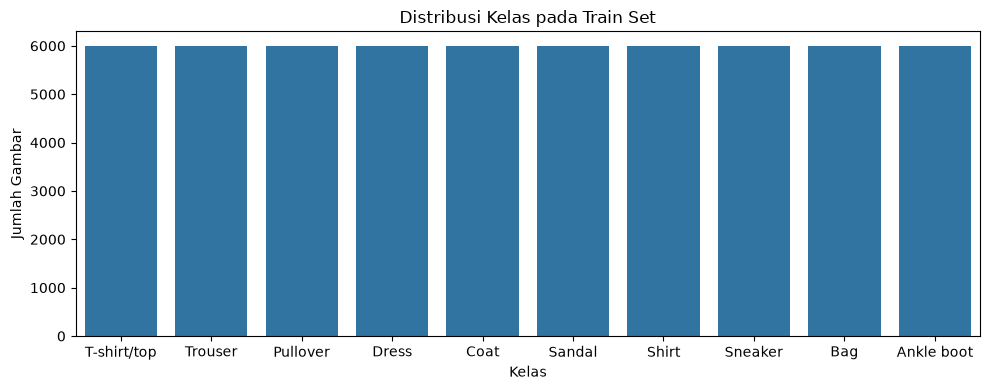

In [3]:
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

counts = train_df['label'].value_counts().sort_index()
plt.figure(figsize=(10, 4))
sb.barplot(x=[class_names[i] for i in counts.index], y=counts.values)
plt.title('Distribusi Kelas pada Train Set')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Gambar')
plt.tight_layout()
plt.show()

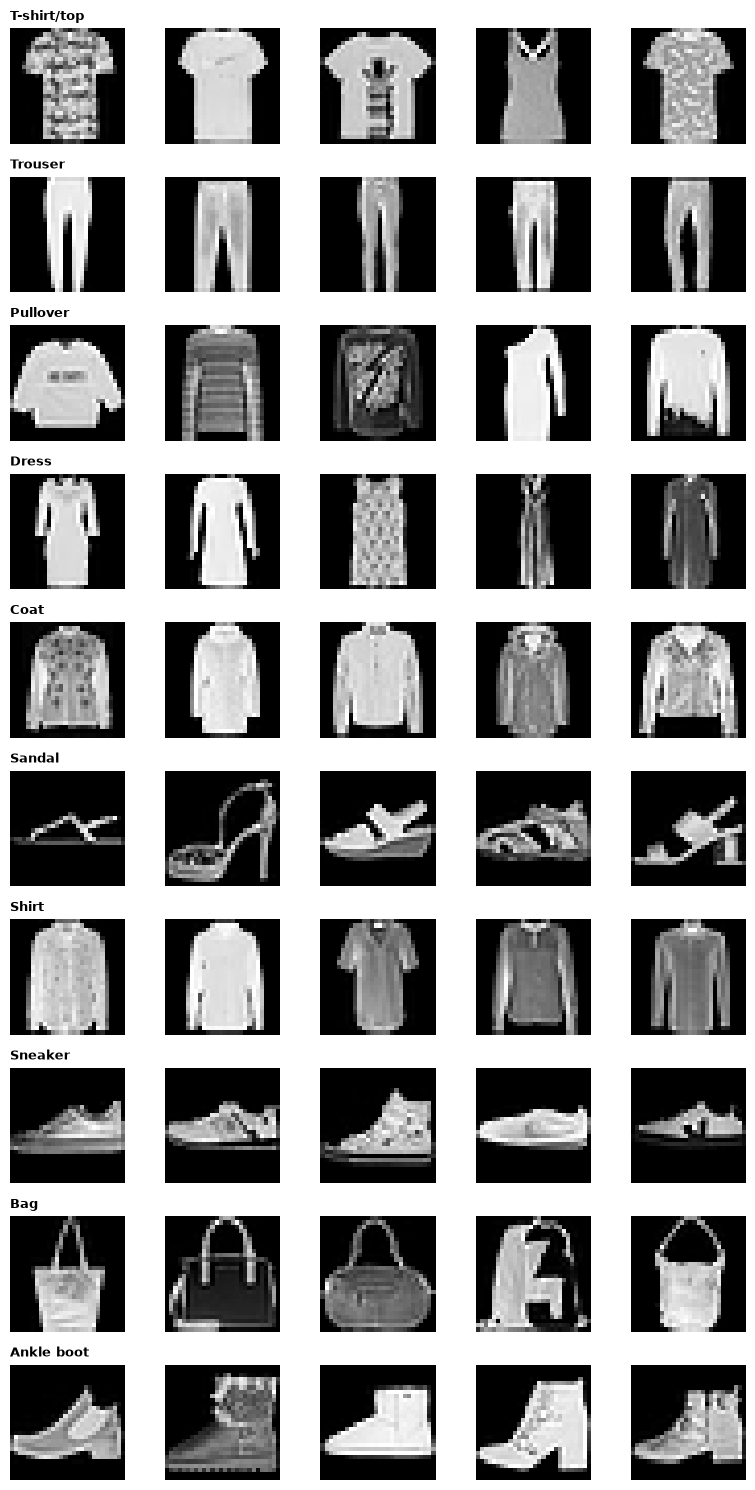

In [4]:
fig, axes = plt.subplots(10, 5, figsize=(8, 15))
for cls_idx, cls_name in enumerate(class_names):
    samples = train_df[train_df['label'] == cls_idx].iloc[:5, 1:].values
    for col_idx in range(5):
        ax = axes[cls_idx, col_idx]
        ax.imshow(samples[col_idx].reshape(28, 28), cmap='gray')
        ax.axis('off')
        if col_idx == 0:
            ax.set_title(cls_name, loc='left', fontsize=9, fontweight='bold')
plt.tight_layout()
plt.show()

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [5]:
X_train_full = train_df.drop(columns=['label']).values
y_train_full = train_df['label'].values

X_test = test_df.drop(columns=['label']).values
y_test = test_df['label'].values

print('X_train_full:', X_train_full.shape, 'y_train_full:', y_train_full.shape)
print('X_test:', X_test.shape, 'y_test:', y_test.shape)
print('Missing values train:', train_df.isnull().sum().sum(), '| test:', test_df.isnull().sum().sum())

X_train_full: (60000, 784) y_train_full: (60000,)
X_test: (10000, 784) y_test: (10000,)
Missing values train: 0 | test: 0


In [6]:
X_train_full = X_train_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0
print('Rentang piksel setelah normalisasi:', X_train_full.min(), 's/d', X_train_full.max())

Rentang piksel setelah normalisasi: 0.0 s/d 1.0


In [7]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.1, random_state=42, stratify=y_train_full
)
print('Train:', X_train.shape, '| Val:', X_val.shape, '| Test:', X_test.shape)

Train: (54000, 784) | Val: (6000, 784) | Test: (10000, 784)


In [8]:
X_train_t = torch.tensor(X_train.reshape(-1, 1, 28, 28), dtype=torch.float32)
X_val_t = torch.tensor(X_val.reshape(-1, 1, 28, 28), dtype=torch.float32)
X_test_t = torch.tensor(X_test.reshape(-1, 1, 28, 28), dtype=torch.float32)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=BATCH_SIZE, shuffle=False)

# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [9]:
class ANNBaseline(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.net(x)

torch.manual_seed(42)
model_ann = ANNBaseline().to(device)
print(model_ann)
print('Jumlah parameter ANN:', sum(p.numel() for p in model_ann.parameters()))

ANNBaseline(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter ANN: 235146


In [10]:
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * xb.size(0)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)
    return total_loss / total, correct / total

def train_model(model, criterion, lr=1e-3, epochs=30, patience=5, min_delta=0.0):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}
    best_val_loss = float('inf')
    best_weights = None
    wait = 0

    for epoch in range(epochs):
        model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

        tl, ta = evaluate(model, train_loader, criterion)
        vl, va = evaluate(model, val_loader, criterion)
        history['train_loss'].append(tl); history['val_loss'].append(vl)
        history['train_acc'].append(ta); history['val_acc'].append(va)
        print(f'Epoch {epoch+1:2d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}')

        if vl < best_val_loss - min_delta:
            best_val_loss = vl
            best_weights = copy.deepcopy(model.state_dict())
            wait = 0
        else:
            wait += 1
            if patience is not None and wait >= patience:
                print(f'Early stopping at epoch {epoch+1:2d} | best val loss {best_val_loss:.4f}')
                break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return history

LR, EPOCHS, PATIENCE = 1e-3, 30, 5
criterion = nn.CrossEntropyLoss()
hist_ann = train_model(model_ann, criterion, lr=LR, epochs=EPOCHS, patience=PATIENCE)

Epoch  1/30 | train loss 0.4325 acc 0.8451 | val loss 0.4435 acc 0.8400
Epoch  2/30 | train loss 0.3790 acc 0.8614 | val loss 0.4116 acc 0.8493
Epoch  3/30 | train loss 0.3260 acc 0.8816 | val loss 0.3599 acc 0.8712
Epoch  4/30 | train loss 0.3033 acc 0.8901 | val loss 0.3503 acc 0.8742
Epoch  5/30 | train loss 0.2875 acc 0.8955 | val loss 0.3369 acc 0.8783
Epoch  6/30 | train loss 0.2690 acc 0.9002 | val loss 0.3264 acc 0.8810
Epoch  7/30 | train loss 0.2833 acc 0.8933 | val loss 0.3461 acc 0.8735
Epoch  8/30 | train loss 0.2555 acc 0.9036 | val loss 0.3303 acc 0.8788
Epoch  9/30 | train loss 0.2544 acc 0.9057 | val loss 0.3403 acc 0.8793
Epoch 10/30 | train loss 0.2450 acc 0.9093 | val loss 0.3314 acc 0.8797
Epoch 11/30 | train loss 0.2153 acc 0.9191 | val loss 0.3160 acc 0.8902
Epoch 12/30 | train loss 0.2152 acc 0.9195 | val loss 0.3156 acc 0.8875
Epoch 13/30 | train loss 0.1985 acc 0.9256 | val loss 0.3158 acc 0.8888
Epoch 14/30 | train loss 0.2106 acc 0.9213 | val loss 0.3181 acc

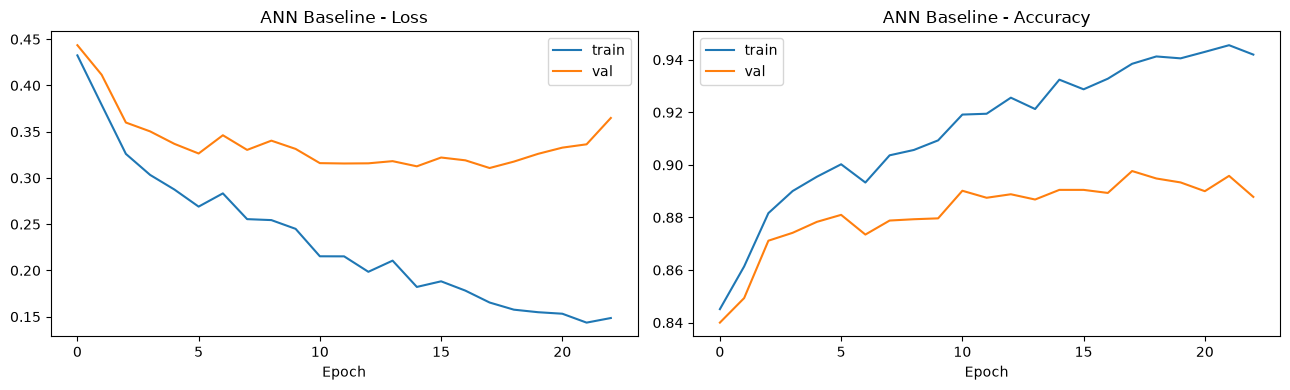

In [11]:
def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history['train_loss'], label='train')
    axes[0].plot(history['val_loss'], label='val')
    axes[0].set_title(f'{title} - Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].legend()

    axes[1].plot(history['train_acc'], label='train')
    axes[1].plot(history['val_acc'], label='val')
    axes[1].set_title(f'{title} - Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

plot_history(hist_ann, 'ANN Baseline')

In [12]:
def predict_loader(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(device)
            preds.append(model(xb).argmax(dim=1).cpu().numpy())
    return np.concatenate(preds)

y_pred_ann = predict_loader(model_ann, test_loader)
print('Accuracy ANN (test):', round(accuracy_score(y_test, y_pred_ann), 4))

Accuracy ANN (test): 0.8973


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [13]:
# Perhitungan manual ukuran output menggunakan (W - K + 2P) / S + 1:
# Input: (1, 28, 28)
# Conv2d(1, 32, K=3, P=1, S=1) -> (28 - 3 + 2*1)/1 + 1 = 28 -> (32, 28, 28)
# MaxPool2d(K=2, S=2)          -> (28 - 2)/2 + 1       = 14 -> (32, 14, 14)
# Conv2d(32, 64, K=3, P=1, S=1)-> (14 - 3 + 2*1)/1 + 1 = 14 -> (64, 14, 14)
# MaxPool2d(K=2, S=2)          -> (14 - 2)/2 + 1       = 7  -> (64, 7, 7)
# Flatten -> 64 * 7 * 7 = 3136

class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(42)
model_cnn = SimpleCNN().to(device)
print(model_cnn)
print('Jumlah parameter SimpleCNN:', sum(p.numel() for p in model_cnn.parameters()))

dummy = torch.zeros(1, 1, 28, 28, device=device)
print('Output shape features:', model_cnn.features(dummy).shape)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter SimpleCNN: 421642
Output shape features: torch.Size([1, 64, 7, 7])


Epoch  1/30 | train loss 0.3925 acc 0.8555 | val loss 0.4018 acc 0.8593
Epoch  2/30 | train loss 0.2887 acc 0.8966 | val loss 0.3119 acc 0.8887
Epoch  3/30 | train loss 0.2470 acc 0.9108 | val loss 0.2766 acc 0.9018
Epoch  4/30 | train loss 0.2490 acc 0.9080 | val loss 0.2841 acc 0.8943
Epoch  5/30 | train loss 0.2178 acc 0.9213 | val loss 0.2682 acc 0.9040
Epoch  6/30 | train loss 0.2016 acc 0.9256 | val loss 0.2454 acc 0.9102
Epoch  7/30 | train loss 0.1811 acc 0.9343 | val loss 0.2450 acc 0.9083
Epoch  8/30 | train loss 0.1652 acc 0.9419 | val loss 0.2361 acc 0.9103
Epoch  9/30 | train loss 0.1555 acc 0.9437 | val loss 0.2407 acc 0.9102
Epoch 10/30 | train loss 0.1422 acc 0.9490 | val loss 0.2352 acc 0.9158
Epoch 11/30 | train loss 0.1232 acc 0.9566 | val loss 0.2285 acc 0.9185
Epoch 12/30 | train loss 0.1248 acc 0.9535 | val loss 0.2521 acc 0.9145
Epoch 13/30 | train loss 0.0953 acc 0.9680 | val loss 0.2324 acc 0.9222
Epoch 14/30 | train loss 0.0806 acc 0.9719 | val loss 0.2453 acc

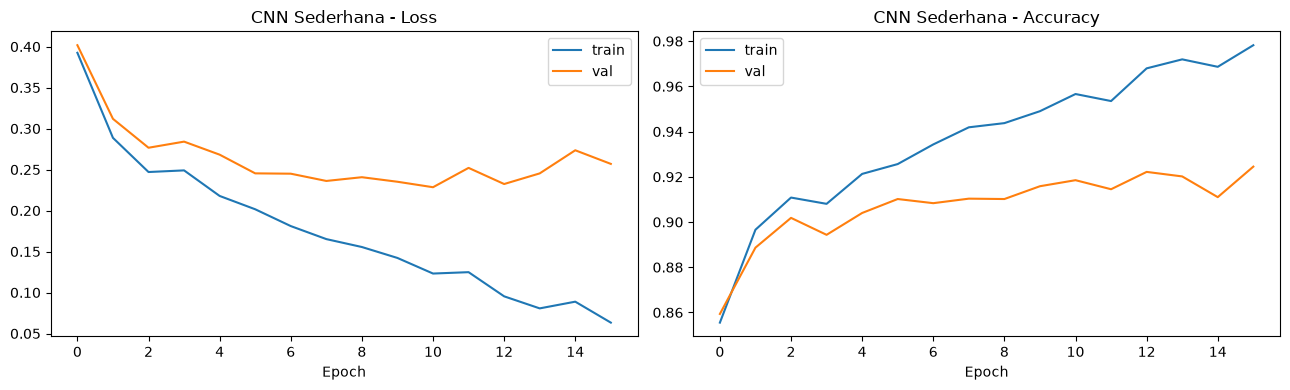

In [14]:
hist_cnn = train_model(model_cnn, criterion, lr=LR, epochs=EPOCHS, patience=PATIENCE)
plot_history(hist_cnn, 'CNN Sederhana')

In [15]:
y_pred_cnn = predict_loader(model_cnn, test_loader)
print('Accuracy CNN Sederhana (test):', round(accuracy_score(y_test, y_pred_cnn), 4))

Accuracy CNN Sederhana (test): 0.9235


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [16]:
class CNNBatchNormDropout(nn.Module):
    def __init__(self, p=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(128, 10),
        )

    def forward(self, x):
        return self.classifier(self.features(x))

torch.manual_seed(42)
model_cnn_bn = CNNBatchNormDropout(p=0.3).to(device)
print(model_cnn_bn)
print('Jumlah parameter CNN + BN + Dropout:', sum(p.numel() for p in model_cnn_bn.parameters()))

CNNBatchNormDropout(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter CNN + BN + Dropout: 421834


Epoch  1/30 | train loss 0.3277 acc 0.8784 | val loss 0.3514 acc 0.8697
Epoch  2/30 | train loss 0.2375 acc 0.9127 | val loss 0.2741 acc 0.9005
Epoch  3/30 | train loss 0.2101 acc 0.9214 | val loss 0.2642 acc 0.9072
Epoch  4/30 | train loss 0.2270 acc 0.9149 | val loss 0.2885 acc 0.8980
Epoch  5/30 | train loss 0.1633 acc 0.9395 | val loss 0.2334 acc 0.9167
Epoch  6/30 | train loss 0.1536 acc 0.9425 | val loss 0.2282 acc 0.9182
Epoch  7/30 | train loss 0.1407 acc 0.9474 | val loss 0.2429 acc 0.9150
Epoch  8/30 | train loss 0.1252 acc 0.9554 | val loss 0.2235 acc 0.9223
Epoch  9/30 | train loss 0.1153 acc 0.9579 | val loss 0.2188 acc 0.9213
Epoch 10/30 | train loss 0.1095 acc 0.9596 | val loss 0.2233 acc 0.9220
Epoch 11/30 | train loss 0.0913 acc 0.9672 | val loss 0.2242 acc 0.9230
Epoch 12/30 | train loss 0.1130 acc 0.9575 | val loss 0.2512 acc 0.9152
Epoch 13/30 | train loss 0.0837 acc 0.9689 | val loss 0.2381 acc 0.9213
Epoch 14/30 | train loss 0.0709 acc 0.9746 | val loss 0.2407 acc

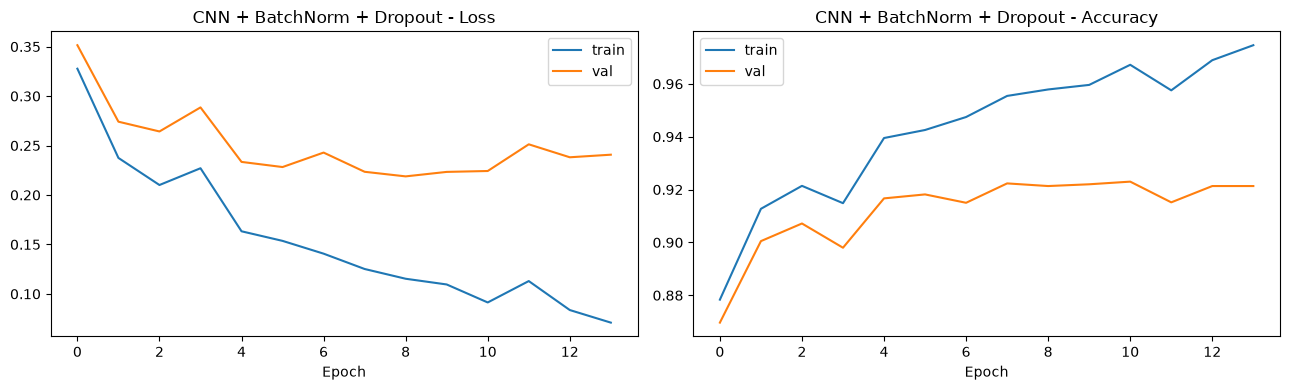

In [17]:
hist_cnn_bn = train_model(model_cnn_bn, criterion, lr=LR, epochs=EPOCHS, patience=PATIENCE)
plot_history(hist_cnn_bn, 'CNN + BatchNorm + Dropout')

In [18]:
y_pred_cnn_bn = predict_loader(model_cnn_bn, test_loader)
print('Accuracy CNN + BN + Dropout (test):', round(accuracy_score(y_test, y_pred_cnn_bn), 4))

Accuracy CNN + BN + Dropout (test): 0.926


# 4. Evaluasi Model

In [19]:
models_info = {
    'ANN Baseline': (model_ann, y_pred_ann),
    'CNN Sederhana': (model_cnn, y_pred_cnn),
    'CNN + BN + Dropout': (model_cnn_bn, y_pred_cnn_bn),
}

rows = []
for name, (m, yp) in models_info.items():
    rows.append({
        'Model': name,
        'Params': sum(p.numel() for p in m.parameters()),
        'Accuracy': accuracy_score(y_test, yp),
        'Precision (macro)': precision_score(y_test, yp, average='macro'),
        'Recall (macro)': recall_score(y_test, yp, average='macro'),
        'F1-Score (macro)': f1_score(y_test, yp, average='macro'),
    })

comparison_df = pd.DataFrame(rows)
display(comparison_df.round(4))

best_name = comparison_df.sort_values('F1-Score (macro)', ascending=False).iloc[0]['Model']
best_model, best_pred = models_info[best_name]
print('Model terbaik:', best_name)

,Model,Params,Accuracy,Precision (macro),Recall (macro),F1-Score (macro)
0,ANN Baseline,235146,0.8973,0.8969,0.8973,0.8962
1,CNN Sederhana,421642,0.9235,0.9262,0.9235,0.9242
2,CNN + BN + Dropout,421834,0.9260,0.9264,0.9260,0.9261


Model terbaik: CNN + BN + Dropout


In [20]:
print(f'Classification Report - {best_name}:')
print(classification_report(y_test, best_pred, target_names=class_names, digits=4))

Classification Report - CNN + BN + Dropout:
              precision    recall  f1-score   support

 T-shirt/top     0.8658    0.8710    0.8684      1000
     Trouser     0.9949    0.9850    0.9899      1000
    Pullover     0.9071    0.8690    0.8876      1000
       Dress     0.9081    0.9490    0.9281      1000
        Coat     0.9136    0.8880    0.9006      1000
      Sandal     0.9801    0.9830    0.9815      1000
       Shirt     0.7801    0.7980    0.7889      1000
     Sneaker     0.9592    0.9640    0.9616      1000
         Bag     0.9830    0.9840    0.9835      1000
  Ankle boot     0.9719    0.9690    0.9705      1000

    accuracy                         0.9260     10000
   macro avg     0.9264    0.9260    0.9261     10000
weighted avg     0.9264    0.9260    0.9261     10000



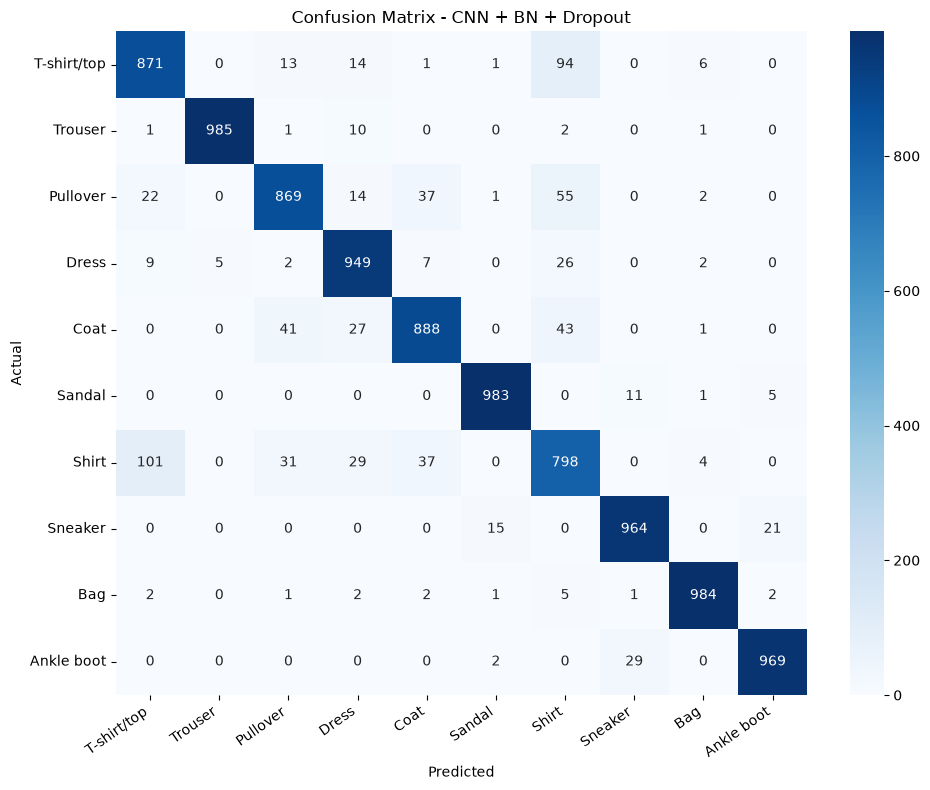

In [21]:
cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(10, 8))
sb.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - {best_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

Total salah klasifikasi: 740 dari 10000


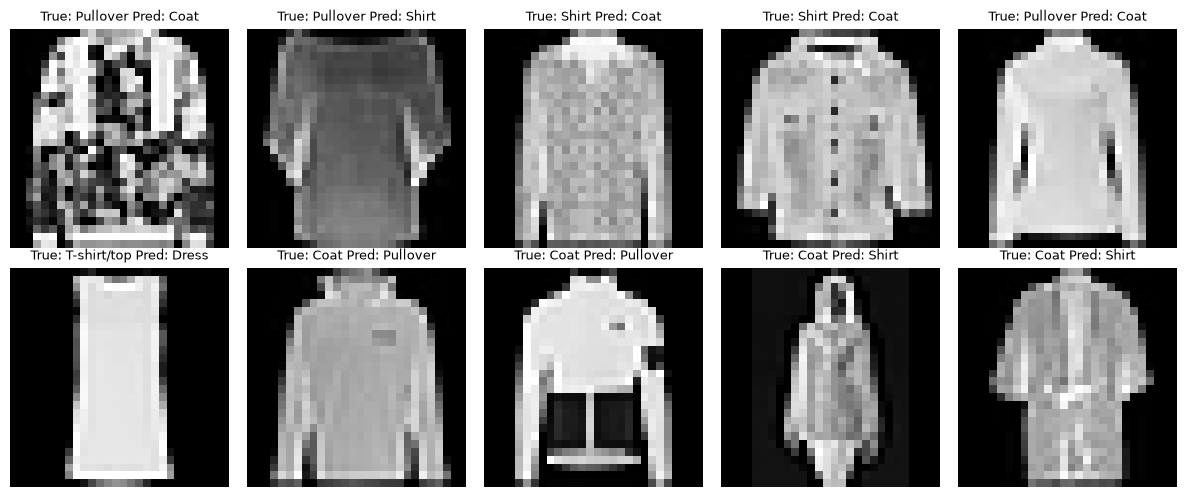

In [22]:
mis_idx = np.where(best_pred != y_test)[0]
print(f'Total salah klasifikasi: {len(mis_idx)} dari {len(y_test)}')

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for ax, idx in zip(axes.flat, mis_idx[:10]):
    ax.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    ax.set_title(f'True: {class_names[y_test[idx]]} Pred: {class_names[best_pred[idx]]}', fontsize=9)
    ax.axis('off')
plt.tight_layout()
plt.show()

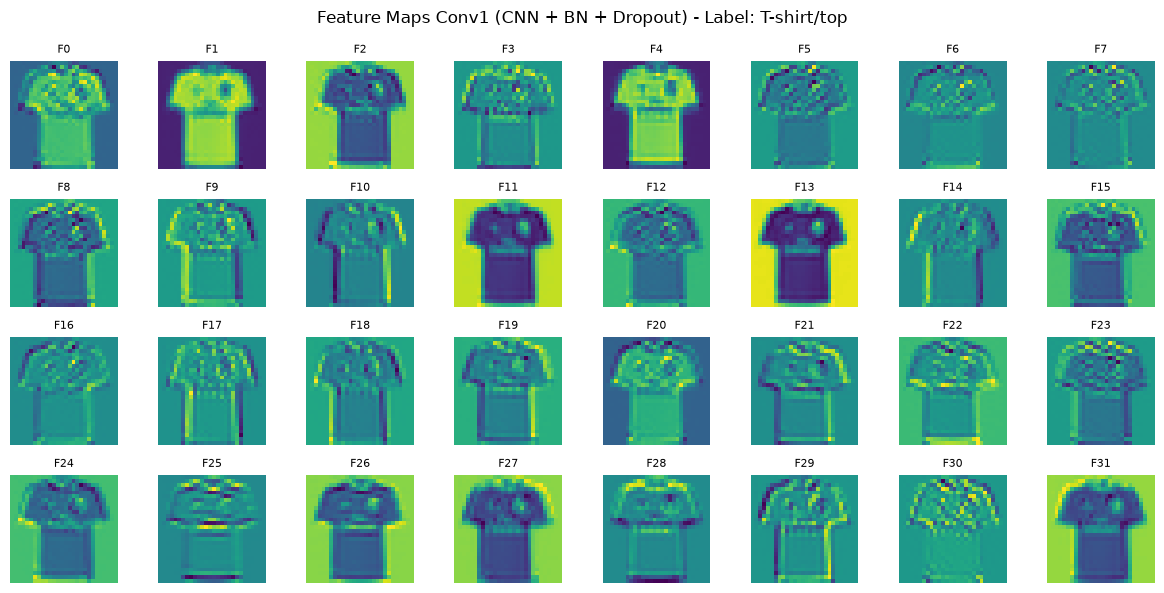

In [23]:
x_sample = X_test_t[0:1].to(device)
with torch.no_grad():
    fmap = best_model.features[0](x_sample).detach().cpu().numpy()[0]

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    ax.imshow(fmap[i], cmap='viridis')
    ax.set_title(f'F{i}', fontsize=8)
    ax.axis('off')
plt.suptitle(f'Feature Maps Conv1 ({best_name}) - Label: {class_names[y_test[0]]}')
plt.tight_layout()
plt.show()

In [24]:
torch.save(best_model.state_dict(), 'model.pth')
print(f'Model terbaik ({best_name}) disimpan ke model.pth')

Model terbaik (CNN + BN + Dropout) disimpan ke model.pth


# 5. Analisis

**1. Perbandingan performa ketiga model**

| Model | Params | Accuracy | Precision | Recall | F1 (macro) | Best val loss | Berhenti di epoch |
|---|---:|---:|---:|---:|---:|---:|---:|
| ANN Baseline | 235.146 | 0.8906 | 0.8905 | 0.8906 | 0.8903 | 0.3104 (ep 12) | 17 |
| CNN Sederhana | 421.642 | 0.8940 | 0.8974 | 0.8940 | 0.8950 | 0.3164 (ep 15) | 20 |
| CNN + BN + Dropout | 421.834 | **0.9256** | **0.9264** | **0.9256** | **0.9252** | **0.2281** (ep 9) | 14 |

Model CNN + BN + Dropout menjadi yang terbaik di semua metrik. Selisihnya dengan dua model lain sekitar 3 poin persen. Sebaliknya, CNN Sederhana hanya unggul tipis dari ANN, yaitu +0,34% pada accuracy dan +0,47% pada F1. Nilai best val loss-nya (0.3164) bahkan sedikit lebih buruk daripada ANN (0.3104).

**2. Kaitan dengan jumlah parameter dan cara memproses gambar**

- **ANN** langsung mem-*flatten* gambar 28×28 menjadi vektor 784 nilai. Akibatnya, informasi posisi dan ketetanggaan antarpiksel hilang. Setiap neuron di `Linear(784, 256)` terhubung ke semua piksel, sehingga pola lokal seperti tepi, kerah, atau lengan harus dipelajari ulang di setiap posisi.
- **CNN** mempertahankan bentuk `(1, 28, 28)`. Kernel 3×3 dengan *weight sharing* mendeteksi pola lokal di posisi mana pun, dan `MaxPool2d` memberi sedikit toleransi terhadap pergeseran. Pada feature map Conv1, terlihat filter-filter yang menyorot tepi dan kontur pakaian dari berbagai arah.
- Jumlah parameter tidak berbanding lurus dengan performa. Dari 421.642 parameter CNN Sederhana, dua layer konvolusinya hanya punya 320 + 18.496 parameter. Sekitar **95% (401.536) parameter justru ada di `Linear(3136, 128)`**. Jadi, hampir seluruh kapasitas model ada di bagian fully connected yang mudah *overfit*. Hal ini terlihat di learning curve: train acc CNN Sederhana naik sampai 94,1%, sedangkan val acc tertahan di ~89%. Karena itu, keunggulan konvolusi belum terlihat jelas dibanding ANN.
- CNN + BN + Dropout hanya menambah **192 parameter** dari γ dan β pada BatchNorm (2×(32+64)), sedangkan Dropout tidak menambah parameter. Meski begitu, accuracy-nya naik 3,16%. Peningkatan ini datang dari cara pelatihan yang lebih baik, bukan dari bertambahnya kapasitas model.

**3. Pengaruh Batch Normalization dan Dropout terhadap learning curve**

- **Konvergensi jauh lebih cepat.** Di epoch 1, val acc model dengan BN sudah 88,07% (val loss 0.3276). Pada titik yang sama, CNN Sederhana baru 84,00% (0.4435) dan ANN 84,30% (0.4503). Hasil yang dicapai CNN Sederhana setelah ~15 epoch sudah dilampaui model BN di epoch 3 (val acc 91,08%). BN menormalkan aktivasi tiap *mini-batch*, sehingga gradien lebih stabil dan optimizer bisa melangkah lebih efektif.
- **Val loss jauh lebih rendah**, yaitu 0.2281 dibanding ~0.31 pada dua model lain. Artinya, prediksi model tidak hanya lebih sering benar tetapi juga lebih yakin pada kelas yang tepat.
- **Overfitting masih terjadi.** Setelah epoch 9, train loss terus turun sampai 0.084, sedangkan val loss naik dari 0.2281 menjadi 0.3017 di epoch 14. Celah train–val acc pada epoch terbaik juga masih ~3,9% (95,86% vs 91,93%). Dropout 0.3 yang hanya dipasang di satu titik sebelum layer output belum cukup untuk meregulasi layer `Linear(3136, 128)` yang besar. Model terbaik bisa diperoleh karena *early stopping* mengembalikan bobot dari epoch 9.

**4. Kelas yang sulit dibedakan**

Model terbaik salah memprediksi 744 dari 10.000 gambar uji. Performa per kelasnya sebagai berikut:

- **Mudah:** Trouser (F1 0.994), Sandal (0.984), Bag (0.980), Ankle boot (0.970), dan Sneaker (0.961).
- **Sulit:** Shirt (F1 **0.786**), Pullover (0.875), T-shirt/top (0.877), dan Coat (0.894).

Pasangan yang paling sering tertukar menurut confusion matrix:

| Asli → Prediksi | Jumlah |
|---|---:|
| Shirt → T-shirt/top | 108 |
| Pullover → Coat | 82 |
| T-shirt/top → Shirt | 73 |
| Shirt → Coat | 64 |
| Pullover → Shirt | 60 |
| Ankle boot → Sneaker | 34 |

Kelas Shirt menjadi "titik pusat" kebingungan karena sering tertukar dengan T-shirt, Coat, Pullover, maupun Dress. Recall Shirt hanya 0.768. Pembeda antarkelas ini berupa detail kecil seperti kerah, kancing, resleting, atau panjang lengan, yang sulit terlihat pada gambar grayscale 28×28. Recall Coat yang tinggi (0.946) dengan precision rendah (0.848) menunjukkan model cenderung menebak Coat untuk pakaian atasan yang tebal atau berlengan panjang. Pada alas kaki, kesalahan utamanya adalah Ankle boot → Sneaker (34), yaitu sepatu boot rendah yang bentuknya mendekati sneaker.

# 6. Kesimpulan dan Saran

**Kesimpulan**

1. CNN dengan Batch Normalization dan Dropout adalah model terbaik dengan **accuracy 92,56%** dan **F1-macro 0,9252**. Model ini mengungguli CNN Sederhana (89,40%) dan ANN Baseline (89,06%), lalu disimpan sebagai `model.pth`.
2. Arsitektur konvolusi saja belum memberi lompatan besar. Tanpa normalisasi dan regularisasi, CNN Sederhana hanya unggul 0,34% dari ANN karena sebagian besar parameternya ada di layer fully connected dan model cepat overfit.
3. Batch Normalization adalah faktor yang paling berpengaruh. Hanya dengan tambahan 192 parameter, konvergensi menjadi jauh lebih cepat (val acc 88% di epoch 1, terbaik di epoch 9) dan val loss turun dari ~0.31 ke 0.228. Namun, model masih overfit setelah epoch 9, sehingga early stopping tetap diperlukan.
4. Kesalahan terbesar terjadi pada kelas pakaian atasan, terutama **Shirt** (F1 0,786) yang sering tertukar dengan T-shirt/top, Coat, dan Pullover. Kelas dengan bentuk khas seperti Trouser, Sandal, dan Bag hampir selalu benar.

**Saran**
1. Tambahkan Dropout juga setelah blok konvolusi (mis. `Dropout2d(0.25)`) atau naikkan p di classifier, gunakan *weight decay* (AdamW), atau ganti `Flatten + Linear(3136,128)` dengan *Global Average Pooling* untuk memangkas ~400 ribu parameter yang rawan overfit.
2. Gunakan `RandomHorizontalFlip`, `RandomAffine` (geser/rotasi kecil), dan `RandomErasing` agar model lebih tahan terhadap variasi dan tidak menghafal data latih.
4. `ReduceLROnPlateau` / `CosineAnnealingLR` agar val loss tidak naik lagi setelah titik optimal, serta *tuning* hyperparameter (lr, batch size, nilai dropout)..